# Spherical Tokamak Neutronics Model: Geometry, Materials and D–T Ring Source

**Notebook 1 of 4** · Base model · OpenMC · nuclear data set in `config.py` (FENDL-3.2)

This notebook builds the baseline OpenMC model that the other three notebooks (TBR / flux / heating / damage, depletion and activation, shutdown dose rate) load and reuse. It defines the materials, the radial build of a spherical tokamak, the D–T plasma source and the run settings, and it calculates the exact cell volumes. Everything is saved as input files in `BASE_DIR`, so the later notebooks only read them and never rebuild the model.

## What the notebook does
- **Materials:** copper central pole, WB₂ protective shield, tungsten first wall and outer shield, Pb-15.8Li breeding blanket with 90 % Li-6, and a steel/water reflector (80 / 20 by volume).
- **Geometry:** a central column (Cu rod r < 20 cm, WB₂ shield 23–53 cm) capped by the outermost sphere, surrounded by concentric shells: first wall (200–201 cm), blanket (201–301 cm), reflector (301–321 cm) and outer shield (321–351 cm). A plasma torus, a vacuum region and a graveyard void complete the model.
- **Source and settings:** a 1-D D–T ring source on the torus major radius (126.5 cm), 20 keV ion temperature, mean birth energy 14.08 MeV, run as a fixed-source calculation with 100 batches of 100 000 particles, survival biasing and coupled neutron–photon transport.
- **Volumes:** exact analytic volumes of all cells, checked against an independent stochastic volume calculation.

## Outputs
`materials.xml`, `geometry.xml`, `settings.xml`, `plots.xml`, the two geometry slice images, `volume_1.h5`, and `geometry_dimensions.csv`, which holds the radii and exact volumes read by the other notebooks.

> Every component is modelled as a single cell, so results in the later notebooks are cell averages. The model demonstrates the calculation workflow and is not an exact reactor design.

In [2]:
import openmc
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import os
import math
import shutil

import numpy as np
import pandas as pd
from openmc_plasma_source import fusion_ring_source

from config import data_library, MODEL_NAME, BASE_DIR

print(openmc.__version__)

0.16.0


In [3]:
# Apply the global library to OpenMC
openmc.config['cross_sections'] = data_library
openmc.reset_auto_ids()

print(f"Model Name: {MODEL_NAME}")
print(f"Results will be saved in: {BASE_DIR}")

Model Name: Spherical_tokamak_fendl
Results will be saved in: ./Spherical_tokamak_fendl_Basic_Configuration


### `MATERIALS`

**Material definitions (consistency check).**
- **WB₂ shield:** built from the formula (1 W : 2 B atoms = 89.5 wt% W / 10.5 wt% B), density 13.0 g/cm³ (the previous typed composition had 12.8 wt% B and 14.8 g/cm³).
- **Reflector:** 80 vol % stainless steel (7.93 g/cm³, 316-type with small Co and Nb impurities) + 20 vol % water (1.0 g/cm³); the mixture density (6.544 g/cm³) is calculated.
- **PbLi:** Pb-15.8Li (90 % Li-6), density 9.4 g/cm³.
- **First wall and outer shield:** natural tungsten, 19.3 g/cm³.
- **Copper rod:** natural copper, 8.96 g/cm³.

In [4]:
# Central Pole - column magnet material
copper_pole = openmc.Material(name="Central Pole (Cu)")
copper_pole.add_nuclide("Cu63", 0.684792, "wo")
copper_pole.add_nuclide("Cu65", 0.315208, "wo")
copper_pole.set_density("g/cm3", 8.96)

#------------------------------------------------------------
# Protective Shield - Tungsten diboride (WB2)
shield_wb = openmc.Material(name='Tungsten diboride (WB2)')
shield_wb.add_elements_from_formula('WB2', percent_type='ao')
shield_wb.set_density('g/cm3', 13.0)

#---------------------------------------------------------------

# Pure natural tungsten (the first wall and the outer shield use the same material definition)
def pure_tungsten(name):
    mat = openmc.Material(name=name)
    mat.add_element('W', 1.0, percent_type='wo')
    mat.set_density('g/cm3', 19.3)
    return mat

# First Wall - Tungsten armor
fw_tungsten = pure_tungsten('First Wall (W)')

#----------------------------------------------------------------

# Breeding Blanket - Liquid Lead-Lithium (Pb-84.2 Li-15.8)
blanket_pbli = openmc.Material(name='Breeding Blanket (PbLi)')
blanket_pbli.set_density('g/cm3', 9.4)

# Atom fractions of Pb-84.2 Li-15.8 and the Li-6 enrichment (each value typed once)
pb_fraction, li_fraction = 0.842, 0.158
li6_enrichment = 0.90
li7_fraction = round(1.0 - li6_enrichment, 6)          # 0.10

# Lead isotopes (84.2% of total atoms, split by natural abundance)
# Pb204 (1.4%), Pb206 (24.1%), Pb207 (22.1%), Pb208 (52.4%)
blanket_pbli.add_nuclide('Pb204', pb_fraction * 0.014, percent_type='ao')
blanket_pbli.add_nuclide('Pb206', pb_fraction * 0.241, percent_type='ao')
blanket_pbli.add_nuclide('Pb207', pb_fraction * 0.221, percent_type='ao')
blanket_pbli.add_nuclide('Pb208', pb_fraction * 0.524, percent_type='ao')

# Lithium isotopes (15.8% of total atoms, enriched to 90% Li-6)
# Li6 (90.0%), Li7 (10.0%)   ------------------------------------------------------------>>>>>>> enriched Lithium (Li-6)
blanket_pbli.add_nuclide('Li6', li_fraction * li6_enrichment, percent_type='ao')
blanket_pbli.add_nuclide('Li7', li_fraction * li7_fraction, percent_type='ao')

'''
Boccaccini, L.V., et al. (2014). 
"Objectives and design of the helium-cooled lead lithium breeding blanket for the EU DEMO." Fusion Engineering and Design, 89(7-8), 1569-1577.
'''
#-----------------------------------------------------------------------

# Outer Shield - Tungsten
shield_tungsten = pure_tungsten('Outer Shield (W)')
#---------------------------------------------------------------------------

# Simple 80% Stainless Steel / 20% Water approximation for the Reflector
steel = openmc.Material(name='Stainless steel (316-type)')
steel_wt = {'Cr': 0.175, 'Ni': 0.1225, 'Mo': 0.025, 'Mn': 0.018, 'Si': 0.005,
            'Co': 0.0005, 'Nb': 0.0001}                       # Fe = the rest
steel.add_element('Fe', 1.0 - sum(steel_wt.values()), percent_type='wo')
for el, w in steel_wt.items():
    steel.add_element(el, w, percent_type='wo')
steel.set_density('g/cm3', 7.93)

water = openmc.Material(name='Water')
water.add_elements_from_formula('H2O')
water.set_density('g/cm3', 1.0)

# mixed 80 / 20 by volume; the density of the mixture is calculated, not typed in
reflector_steel = openmc.Material.mix_materials([steel, water], [0.8, 0.2], 'vo', name='Steel Reflector')

#-------------------------------------------------------------------------

materials = openmc.Materials([copper_pole, shield_wb, fw_tungsten, blanket_pbli, reflector_steel, shield_tungsten])
materials.cross_sections = data_library
original_mats_path = os.path.join(BASE_DIR, 'materials.xml')
materials.export_to_xml(original_mats_path)
print(f"materials.xml saved to {BASE_DIR}")

materials.xml saved to ./Spherical_tokamak_fendl_Basic_Configuration


# `GEOMETRY`

# SURFACES (Parameterized by Thickness)

In [5]:
# Radial build (cm): the thicknesses are the inputs, the radii follow from them
t_fw = 1.0          # Thinned First Wall: 1.0 cm
t_blanket = 100.0   # Thickened Blanket: 100.0 cm
t_reflector = 20.0  # New Steel Reflector: 20.0 cm
t_outer = 30.0      # Outer Shield: 30.0 cm

# Central column (Cu rod r < 20, WB2 shield 23 < r < 53)
r_cu_in      = 0.0
r_cu_out     = 20.0
r_shield_in  = 23.0
r_shield_out = 53.0

# Spherical shells: each shell starts where the previous one ends
r_fw_in       = 200.0                      # plasma-facing vacuum radius
r_fw_out      = r_fw_in + t_fw             # 201.0 cm
r_blanket_in  = r_fw_out
r_blanket_out = r_blanket_in + t_blanket   # 301.0 cm
r_mirror_in   = r_blanket_out
r_mirror_out  = r_mirror_in + t_reflector  # 321.0 cm
r_outer_in    = r_mirror_out
r_outer_out   = r_outer_in + t_outer       # 351.0 cm

# The central column is capped by the outermost sphere, so its half-length equals that radius
z_bound = r_outer_out

# Cylinders for the central column (r = 20, 23, 53)
cu_cyl = openmc.ZCylinder(r=r_cu_out)
shield_in_cyl = openmc.ZCylinder(r=r_shield_in)
shield_out_cyl = openmc.ZCylinder(r=r_shield_out)

# Concentric spherical boundaries
vac_sphere = openmc.Sphere(r=r_fw_in)
fw_sphere = openmc.Sphere(r=r_fw_out)
blanket_sphere = openmc.Sphere(r=r_blanket_out)
mirror_sphere = openmc.Sphere(r=r_mirror_out)

# The outer shield boundary is NOT the vacuum boundary
outer_sphere = openmc.Sphere(r=r_outer_out)

# Outermost global boundary ( must have boundary_type='vacuum' to terminate particles - so that particles can be located that did not leak out for SDDR calculations
graveyard_sphere = openmc.Sphere(r=500.0, boundary_type='vacuum')

# Plasma Torus Surface
t1 = openmc.ZTorus(a=126.5, b=100.0, c=50.0)

# CELLS & REGIONS

In [12]:

# Copper Magnet Rod (Solid core r < 20, cleanly capped by the outer sphere itself) 
region_cu = -cu_cyl & -outer_sphere
cell_cu = openmc.Cell(name='Copper Magnet Rod', fill=copper_pole, region=region_cu) 

# Protective Shield (Annulus r between 23 and 53, cleanly capped by the outer sphere itself) 
region_shield = +shield_in_cyl & -shield_out_cyl & -outer_sphere
cell_shield = openmc.Cell(name='Protective Shield', fill=shield_wb, region=region_shield) 

# First Wall (r between 200 and 201, OUTSIDE the r=53 central cylinder) 
region_fw = +shield_out_cyl & +vac_sphere & -fw_sphere 
cell_fw = openmc.Cell(name='First Wall', fill=fw_tungsten, region=region_fw) 

# Breeding Blanket (r between 201 and 301, OUTSIDE the r=53 central cylinder) 
region_blanket = +shield_out_cyl & +fw_sphere & -blanket_sphere 
cell_blanket = openmc.Cell(name='Breeding Blanket', fill=blanket_pbli, region=region_blanket) 

# Neutron Reflector (r between 301 and 321, OUTSIDE the r=53 central cylinder) 
region_mirror = +shield_out_cyl & +blanket_sphere & -mirror_sphere 
cell_mirror = openmc.Cell(name='Reflector', fill=reflector_steel, region=region_mirror) 

# Outer Shield (r between 321 and 351, OUTSIDE the r=53 central cylinder) 
region_outer = +shield_out_cyl & +mirror_sphere & -outer_sphere 
cell_outer = openmc.Cell(name='Outer Shield', fill=shield_tungsten, region=region_outer) 

# Plasma Torus Cell (Filled with vacuum) 
region_plasma = -t1
cell_plasma = openmc.Cell(name='Plasma', fill=None, region=region_plasma) 

# Remaining Internal Vacuum (Empty space inside the outer shield sphere not occupied by solids/plasma) 
solid_regions = ( 
    region_cu | region_shield | region_fw |  
    region_blanket | region_mirror | region_outer 
) 
cell_vac = openmc.Cell(name='Vacuum Space', fill=None) 
cell_vac.region = -outer_sphere & ~solid_regions & ~region_plasma 

# Global Void "Graveyard" (Empty space between the reactor and the absolute boundary)
cell_graveyard = openmc.Cell(name='Graveyard Void', fill=None, region=+outer_sphere & -graveyard_sphere)

# Export Geometry 
geometry = openmc.Geometry([ 
    cell_cu, cell_shield, cell_fw, cell_blanket,  
    cell_mirror, cell_outer, cell_plasma, cell_vac, cell_graveyard
]) 
geometry.export_to_xml(os.path.join(BASE_DIR, 'geometry.xml')) 
print(f"Geometry.xml saved to {BASE_DIR}")

Geometry.xml saved to ./Spherical_tokamak_fendl_Basic_Configuration


# `Plotting` 

                                %%%%%%%%%%%%%%%
                           %%%%%%%%%%%%%%%%%%%%%%%%
                        %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                      %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                    %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                   %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                                    %%%%%%%%%%%%%%%%%%%%%%%%
                                     %%%%%%%%%%%%%%%%%%%%%%%%
                 ###############      %%%%%%%%%%%%%%%%%%%%%%%%
                ##################     %%%%%%%%%%%%%%%%%%%%%%%
                ###################     %%%%%%%%%%%%%%%%%%%%%%%
                ####################     %%%%%%%%%%%%%%%%%%%%%%
                #####################     %%%%%%%%%%%%%%%%%%%%%
                ######################     %%%%%%%%%%%%%%%%%%%%
                #######################     %%%%%%%%%%%%%%%%%%
                 #######################     %%%%%%%%%%%%%%%%%
                 #####################

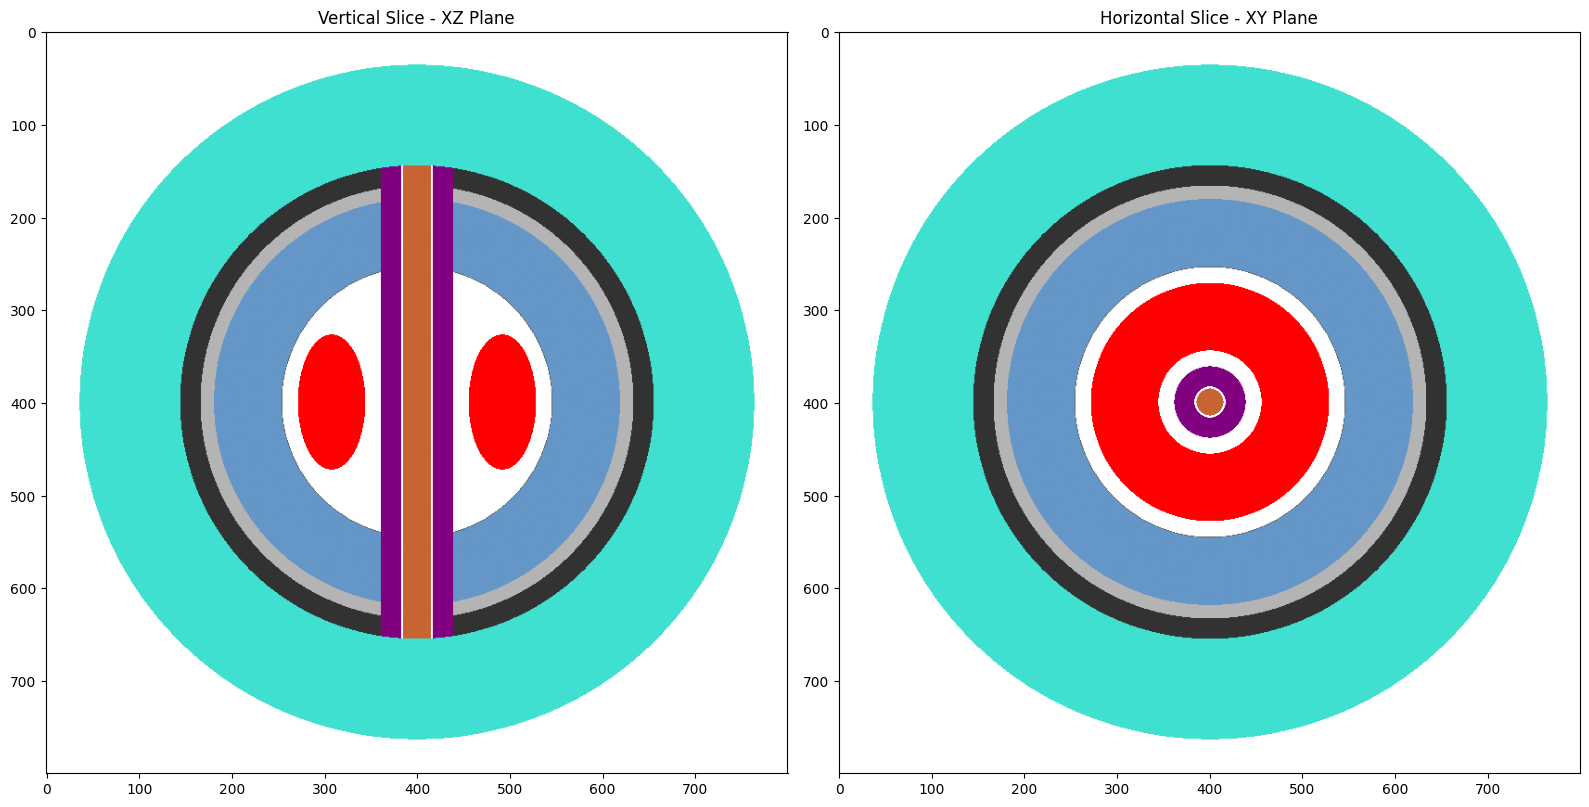

Geometry generated and is saved in ./Spherical_tokamak_fendl_Basic_Configuration


In [14]:
# Colouring cells
shared_colors = {
    cell_cu:        (200, 100, 50),    # Copper Rod: Bronze/Orange
    cell_shield:    (128, 0, 128),     # Central Shield: Purple
    cell_fw:        (100, 100, 100),   # First Wall (1 cm): Dark Gray
    cell_blanket:   (100, 150, 200),   # PbLi Blanket (100 cm): Light Blue
    cell_mirror:    (180, 180, 180),   # Steel Reflector (20 cm): Silver/Light Gray
    cell_outer:    (50, 50, 50),      # Outer Shield (30 cm): Black
    cell_plasma:    (255, 0, 0),       # Plasma Core: Red
    cell_vac:       (255, 255, 255),   # Vacuum Chamber: White
    cell_graveyard: (64, 224, 208)     # Graveyard Void: Turquoise
}

# Slice plot (same settings for the vertical and the horizontal slice)
def slice_plot(basis):
    plot = openmc.SlicePlot()
    plot.filename = f'ST_radial_build_{basis}'
    plot.basis = basis
    plot.origin = (0.0, 0.0, 0.0)
    plot.width = (1100.0, 1100.0)
    plot.pixels = (800, 800)
    plot.color_by = 'cell'
    plot.colors = shared_colors
    return plot

plot_xz = slice_plot('xz')      # Vertical slice
plot_xy = slice_plot('xy')      # Horizontal slice

# Export to XML and generate and save the PNG files
plots = openmc.Plots([plot_xz, plot_xy])
plots.export_to_xml(os.path.join(BASE_DIR, 'plots.xml'))
openmc.plot_geometry(cwd=BASE_DIR)


# Image display
img_xz = os.path.join(BASE_DIR, f'{plot_xz.filename}.png')
img_xy = os.path.join(BASE_DIR, f'{plot_xy.filename}.png')


fig, axes = plt.subplots(1, 2, figsize=(16, 8))

#Veritcal Slice
axes[0].imshow(mpimg.imread(img_xz))
axes[0].set_title('Vertical Slice - XZ Plane')

#Horizontal Slice
axes[1].imshow(mpimg.imread(img_xy))
axes[1].set_title('Horizontal Slice - XY Plane')

plt.tight_layout()
plt.show()


print(f"Geometry generated and is saved in {BASE_DIR}")

# RING SOURCE

Reference - Delaporte-Mathurin, R., Shimwell, J., Pattinson, L., Pranto, A. I., & Faisal, M. (2023). OpenMC Plasma Source (Version 0.3.0) [Computer software]. https://github.com/fusion-energy/openmc-plasma-source

### SETTINGS and RING SOURCE


Neutron Energy Context:
The D-T fusion reaction (D + T -> n + alpha) yields a total energy (Q-value) of roughly 17.59 MeV. 
Based on the conservation of momentum, the lighter neutron carries away approximately 80% of this energy, 
resulting in a mean birth energy of 14.08 MeV. 

Because the plasma is extremely hot (20 keV), the thermal motion of the reacting ions causes Doppler 
broadening. The openmc_plasma_source package models this physical effect using OpenMC's Muir energy 
distribution (openmc.stats.Muir), generating a Gaussian spectrum centered at 14.08 MeV. 
The mathematical derivation is documented in the official OpenMC formulation guide and originates 
from J. Brysk's 1973 journal article "Fusion neutron energies and spectra" in Plasma Physics.


In [7]:

settings = openmc.Settings()
settings.run_mode = "fixed source"
settings.batches = 100
settings.inactive = 20
settings.particles = 100000
# Enable coupled transport in settings before creating the model
settings.photon_transport = True




# Define the 1D ring source
ring_source = fusion_ring_source(
    radius=t1.a,                 # Matches the major radius of the torus (t1.a = 126.5 cm)
    start_angle=0.0,             # Start at 0 radians
    rotation_angle=2 * math.pi,  # Full 360-degree 
    temperature=20000.0,         # 20 keV plasma
    fuel={"D": 0.5, "T": 0.5}    # 50/50 D-T mix yielding 14.1 MeV neutrons

#OpenMC natively defaults all new source strengths to exactly 1.0 automatically

)

'''
for src in ring_source:
    src.strength = 1.0

'''

# Apply to OpenMC settings
settings.source = ring_source
settings.survival_biasing = True
settings_path = os.path.join(BASE_DIR, 'settings.xml')
settings.export_to_xml(settings_path)

print(f"Settings and fusion ring source successfully exported to {BASE_DIR}")
print(f"Materials, Geometry, Settings, everything else saved in {BASE_DIR}")

Settings and fusion ring source successfully exported to ./Spherical_tokamak_fendl_Basic_Configuration
Materials, Geometry, Settings, everything else saved in ./Spherical_tokamak_fendl_Basic_Configuration


### Cell volumes
Every cell is a simple shape, so its volume has an exact formula: a spherical shell of outer/inner radius R₂/R₁ outside the central cylinder of radius r_c = 53 cm has
V = 4/3 π [(R₂² − r_c²)^1.5 − (R₁² − r_c²)^1.5]; the copper rod is a cylinder V = π r² h and the WB₂ shield an annulus V = π (r₂² − r₁²) h with h = 702 cm.
These exact volumes are used for DPA, activation and dose. The random-sampling (stochastic) calculation below is only kept as an independent cross-check
(its error is about 1 % for the 1 cm thick first wall).

In [8]:
def sphere_outside_cyl(R, rc):
    # volume of a sphere of radius R that lies OUTSIDE the central cylinder r < rc
    return 4.0 / 3.0 * math.pi * (R**2 - rc**2) ** 1.5

# Volume of the full outermost sphere
vol_total_sphere = (4.0 / 3.0) * math.pi * (r_outer_out**3)


# Volume of a cylinder inside a sphere = Total Sphere Vol - Sphere Vol outside the cylinder
vol_cu      = vol_total_sphere - sphere_outside_cyl(r_outer_out, r_cu_out)
vol_shield  = sphere_outside_cyl(r_outer_out, r_shield_in) - sphere_outside_cyl(r_outer_out, r_shield_out)

vol_fw      = sphere_outside_cyl(r_fw_out, r_shield_out) - sphere_outside_cyl(r_fw_in, r_shield_out)
vol_blanket = sphere_outside_cyl(r_blanket_out, r_shield_out) - sphere_outside_cyl(r_blanket_in, r_shield_out)
vol_mirror  = sphere_outside_cyl(r_mirror_out, r_shield_out) - sphere_outside_cyl(r_mirror_in, r_shield_out)
vol_outer   = sphere_outside_cyl(r_outer_out, r_shield_out) - sphere_outside_cyl(r_outer_in, r_shield_out)

# Components table (the TBR, depletion and SDDR notebooks copy this table): the cell and its analytic volume
components = {
    'First Wall':        dict(cell=cell_fw,      vol=vol_fw),
    'Protective Shield': dict(cell=cell_shield,  vol=vol_shield),
    'Breeding Blanket':  dict(cell=cell_blanket, vol=vol_blanket),
    'Reflector':         dict(cell=cell_mirror,  vol=vol_mirror),
    'Copper Magnet Rod': dict(cell=cell_cu,      vol=vol_cu),
    'Outer Shield':      dict(cell=cell_outer,   vol=vol_outer),
}

#-------------------------------------------------------------------------------------------------------------------#

#Random-sampling (stochastic) calculation for volume.

#OpenMC Stochastic Volume Calculation

# Cells in the geometry block
solid_cells = [comp['cell'] for comp in components.values()]


lower_left = [-r_outer_out, -r_outer_out, -r_outer_out]
upper_right = [r_outer_out, r_outer_out, r_outer_out]

vol_calc = openmc.VolumeCalculation(
    domains=solid_cells,
    samples=50_000_000,
    lower_left=lower_left,
    upper_right=upper_right
)

# Back up the real settings.xml (settings_path, defined in cell 15) to add the volume settings
backup_path = os.path.join(BASE_DIR, 'settings_backup.xml')
if os.path.exists(settings_path):
    shutil.copy(settings_path, backup_path)

# Create a temporary settings just for the volume calculation
vol_settings = openmc.Settings()
vol_settings.volume_calculations = [vol_calc]
vol_settings.export_to_xml(BASE_DIR)

# Run OpenMC volume stochastic calculation
openmc.calculate_volumes(cwd=BASE_DIR)

# Load the results
vol_results = openmc.VolumeCalculation.from_hdf5(os.path.join(BASE_DIR, 'volume_1.h5'))

# Cleanup backup
if os.path.exists(backup_path):
    shutil.move(backup_path, settings_path)
else:
    os.remove(settings_path)

#----------------------------------------------------------------------------------------------------------------
# DataFrame of the geometry dimensions and exact volumes (built from the r_* names and the vol_* volumes)
geom_df = pd.DataFrame({
    "Component": [
        "Copper Magnet Rod (Central)",
        "Protective Shield (Central)",
        "First Wall (Spherical)",
        "Breeding Blanket (Spherical)",
        "Steel Reflector (Spherical)",
        "Outer Shield (Spherical)",
        "Plasma Torus"
    ],
    "Inner Radius (cm)": [
        r_cu_in,
        r_shield_in,
        r_fw_in,
        r_blanket_in,
        r_mirror_in,
        r_outer_in,
        f"Major a: {t1.a}"
    ],
    "Outer Radius (cm)": [
        r_cu_out,
        r_shield_out,
        r_fw_out,
        r_blanket_out,
        r_mirror_out,
        r_outer_out,
        f"Minor b: {t1.b}, c: {t1.c}"
    ],
    "Thickness (cm)": [
        r_cu_out - r_cu_in,
        r_shield_out - r_shield_in,
        r_fw_out - r_fw_in,
        r_blanket_out - r_blanket_in,
        r_mirror_out - r_mirror_in,
        r_outer_out - r_outer_in,
        "-"
    ],
    "Z-Length (cm)": [
        f"Spherical Cap (R={z_bound:g})",
        f"Spherical Cap (R={z_bound:g})",
        "Spherical Shell",
        "Spherical Shell",
        "Spherical Shell",
        "Spherical Shell",
        "Torus"
    ],
    "Volume (cm^3)": [
        vol_cu,
        vol_shield,
        vol_fw,
        vol_blanket,
        vol_mirror,
        vol_outer,
        0.0  # Plasma Torus
    ]
})

# Save as the single source of truth (read by the TBR, depletion and SDDR notebooks)
geom_csv_path = os.path.join(BASE_DIR, 'geometry_dimensions.csv')
geom_df.to_csv(geom_csv_path, index=False)

print(f"Geometry dimensions and exact volumes saved to {geom_csv_path}")
display(geom_df)


print("\n Volume Verification")
for name, comp in components.items():
    vs_ = vol_results.volumes[comp['cell'].id]
    print(f"{name:20s} exact {comp['vol']:.4e} | sampled {vs_.n:.4e} +- {vs_.s:.1e} | difference {100*(vs_.n/comp['vol']-1):+.2f} %")


                                %%%%%%%%%%%%%%%
                           %%%%%%%%%%%%%%%%%%%%%%%%
                        %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                      %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                    %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                   %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                                    %%%%%%%%%%%%%%%%%%%%%%%%
                                     %%%%%%%%%%%%%%%%%%%%%%%%
                 ###############      %%%%%%%%%%%%%%%%%%%%%%%%
                ##################     %%%%%%%%%%%%%%%%%%%%%%%
                ###################     %%%%%%%%%%%%%%%%%%%%%%%
                ####################     %%%%%%%%%%%%%%%%%%%%%%
                #####################     %%%%%%%%%%%%%%%%%%%%%
                ######################     %%%%%%%%%%%%%%%%%%%%
                #######################     %%%%%%%%%%%%%%%%%%
                 #######################     %%%%%%%%%%%%%%%%%
                 #####################

,Component,Inner Radius (cm),Outer Radius (cm),Thickness (cm),Z-Length (cm),Volume (cm^3)
0,Copper Magnet Rod (Central),0.0,20.0,20.0,Spherical Cap (R=351),8.814428e+05
1,Protective Shield (Central),23.0,53.0,30.0,Spherical Cap (R=351),4.994114e+06
2,First Wall (Spherical),200.0,201.0,1.0,Spherical Shell,4.872032e+05
3,Breeding Blanket (Spherical),201.0,301.0,100.0,Spherical Shell,7.843064e+07
4,Steel Reflector (Spherical),301.0,321.0,20.0,Spherical Shell,2.396142e+07
5,Outer Shield (Spherical),321.0,351.0,30.0,Spherical Shell,4.205624e+07
6,Plasma Torus,Major a: 126.5,"Minor b: 100.0, c: 50.0",-,Torus,0.000000e+00



 Volume Verification
First Wall           exact 4.8720e+05 | sampled 4.9180e+05 +- 1.8e+03 | difference +0.94 %
Protective Shield    exact 4.9941e+06 | sampled 5.0039e+06 +- 5.8e+03 | difference +0.20 %
Breeding Blanket     exact 7.8431e+07 | sampled 7.8475e+07 +- 2.0e+04 | difference +0.06 %
Reflector            exact 2.3961e+07 | sampled 2.3952e+07 +- 1.2e+04 | difference -0.04 %
Copper Magnet Rod    exact 8.8144e+05 | sampled 8.8281e+05 +- 2.5e+03 | difference +0.16 %
Outer Shield         exact 4.2056e+07 | sampled 4.2052e+07 +- 1.6e+04 | difference -0.01 %
